# V6.5-26 — Student n cho Pi: train ở 640 vs 800 (vết lỗi nhỏ) — log mAP50 / mAP50-95 / gap từng lớp mỗi epoch

**Câu hỏi:** student train ở ảnh lớn hơn có bắt được vết lỗi nhỏ mà Pi đang sót không? (n_v5 sót 32% ảnh có
insulator_broken < 1% diện tích ảnh, chỉ 7% với vết vừa/lớn.) Hai lượt **cùng công thức, chỉ khác imgsz**:
khởi từ student n_v5, distill từ teacher v5_orig, dataset **v6p5_v9** (không rò val, test_fo để riêng), AdamW lr 1e-4,
không warmup (lr 1e-3 + warmup từng phá student đã hội tụ), tắt mosaic 5 epoch cuối, 20 epoch, seed cố định, val mỗi epoch.

**Đọc số cho đúng:**
- *Mỗi epoch* (cell 3–5): ultralytics val trên **toàn bộ val_clean_v8** (gồm 148 ảnh rò, letterbox rect) → chỉ để xem
  xu hướng và **gap = mAP50 − mAP50-95** (gap lớn = tìm ra lỗi nhưng box lệch / quy ước box chưa nhất quán).
- *Kết luận* (cell 6): **val_clean_v8 bỏ ảnh rò**, letterbox vuông như NCNN trên Pi, so ghép cặp với n_v5.
- Bản 800 chạy chậm hơn ~1.56× trên Pi: chỉ đáng dùng nếu Pi 3 kham nổi (đo bằng `artifacts/pi_v8.zip`).

**Chạy nền** (Windows, ~6.5 giờ trên RTX 4060 laptop): xem `artifacts/exp_student_res/progress.log` (mỗi epoch 1 dòng) và
`per_class_epochs.csv`. Bị ngắt → chạy lại: lượt xong thì bỏ qua, lượt dở thì resume. Thử nhanh: `DRY_RUN = True`.

In [1]:
# 1. CẤU HÌNH
import os, sys, time, json, shutil
from pathlib import Path
import numpy as np, pandas as pd, torch
from ultralytics import YOLO

SIZES = [640, 800]                    # imgsz train + đánh giá của từng lượt (vuông, như NCNN trên Pi)
EPOCHS, BATCH, LR = 20, 8, 1e-4
DRY_RUN = os.environ.get("DRY_RUN", "0") == "1"   # 1 epoch, 2% ảnh, imgsz 320 → thử notebook ~5 phút

REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").is_file() and (p / "notebooks").is_dir())
DS9 = REPO / "datasets/v6p5_v9"; DS8 = REPO / "datasets/v6p5_v8"
INIT = REPO / "artifacts/v6p5_v6_teachers/init/student_n_v5.pt"
TEACHER = REPO / "artifacts/v6p5_v6_teachers/init/teacher_v5.pt"
OUT = REPO / ("artifacts/exp_student_res" + ("_dryrun" if DRY_RUN else "")); OUT.mkdir(parents=True, exist_ok=True)
LOG, EPOCH_CSV = OUT / "progress.log", OUT / "per_class_epochs.csv"
NAMES = ["insulator", "insulator_broken", "insulator_flashover", "bird_nest", "foreign_object", "broken_strand", "person"]
DEFECTS = NAMES[1:6]; SHORT = ["broken", "flashover", "bird_nest", "FO", "strand"]
if DRY_RUN: SIZES, EPOCHS = [320], 1

def log(m):
    print(m, flush=True)
    with open(LOG, "a", encoding="utf-8") as f: f.write(f"{time.strftime('%m-%d %H:%M')} {m}\n")
log(f"===== start | GPU {torch.cuda.get_device_name(0)} | sizes {SIZES} × {EPOCHS} ep | DRY_RUN {DRY_RUN}")

===== start | GPU NVIDIA GeForce RTX 4060 Laptop GPU | sizes [640, 800] × 20 ep | DRY_RUN False


In [2]:
# 2. KIỂM TRA: dataset v9 + cache .npy (hard link từ v5) + weights + danh sách val không rò (cho cell 6)
assert (DS9 / "manifest.json").is_file(), "thiếu datasets/v6p5_v9 → python scripts/build_v9.py --v8 datasets/v6p5_v8 --out datasets/v6p5_v9"
assert INIT.is_file() and TEACHER.is_file(), "thiếu weights v5 (notebooks/08 cell 5)"
n = 0
for img in (DS9 / "images/train").glob("*.jpg"):     # ảnh v9 = ảnh v5 → dùng chung cache, khỏi tạo lại ~55 GB
    src, dst = REPO / "datasets/v6p5_v5/images/train" / (img.stem + ".npy"), img.with_suffix(".npy")
    if not dst.exists() and src.exists(): os.link(src, dst); n += 1
leak = set((DS9 / "leaked_val.txt").read_text().split())
NOLEAK = sorted(p for p in (DS9 / "images/val_clean_v8").glob("*.jpg") if p.name not in leak)
(DS9 / "val_clean_v8_noleak.txt").write_text("\n".join(str(p) for p in NOLEAK) + "\n")
yaml_noleak = DS9 / "data_val_noleak.yaml"
yaml_noleak.write_text(f"path: {DS9}\ntrain: images/train\nval: {DS9 / 'val_clean_v8_noleak.txt'}\nnames:\n" +
                       "".join(f"  {i}: {n_}\n" for i, n_ in enumerate(NAMES)))
st = json.loads((DS9 / "manifest.json").read_text())["stats"]["train"]
log(f"v9 train {st['images']} ảnh (FO {st['box:foreign_object']}) | cache mới link {n} | val không rò {len(NOLEAK)} ảnh")

v9 train 17417 ảnh (FO 574) | cache mới link 0 | val không rò 2123 ảnh


In [3]:
# 3. LOG MỖI EPOCH: AP50, AP50-95, gap của từng lớp (ultralytics val trên val_clean_v8 mỗi epoch) → CSV + progress.log
def epoch_logger(tr):
    b = getattr(getattr(tr, "validator", None), "metrics", None)
    if b is None: return
    b = b.box; row = {"arm": tr.args.name, "epoch": tr.epoch + 1, "min": round((time.time() - tr.train_time_start) / 60, 1)}
    for i, c in enumerate(b.ap_class_index):
        k = NAMES[int(c)]; row[f"{k}|50"] = float(b.ap50[i]); row[f"{k}|5095"] = float(b.ap[i])
    m50 = np.mean([row.get(f"{k}|50", np.nan) for k in DEFECTS]); m95 = np.mean([row.get(f"{k}|5095", np.nan) for k in DEFECTS])
    row["MEAN_5|50"], row["MEAN_5|5095"] = m50, m95
    final = tr.epoch + 1 > tr.epochs   # ultralytics đo lại best.pt sau epoch cuối → không ghi vào bảng theo epoch
    if not final: pd.DataFrame([row]).to_csv(EPOCH_CSV, mode="a", header=not EPOCH_CSV.exists(), index=False)
    cls = " | ".join(f"{s} {row.get(k + '|50', np.nan):.3f}/{row.get(k + '|5095', np.nan):.3f} (gap {row.get(k + '|50', np.nan) - row.get(k + '|5095', np.nan):.2f})"
                     for k, s in zip(DEFECTS, SHORT))
    tag = "best.pt (val cuối)" if final else f"ep {tr.epoch + 1:>2}/{tr.epochs}"
    log(f"[{tr.args.name}] {tag} {row['min']:>5.0f}′ | MEAN_5 {m50:.3f}/{m95:.3f} (gap {m50 - m95:.3f}) | {cls}")

In [4]:
# 4. TRAIN từng lượt (bỏ qua nếu xong, resume nếu dở). Mỗi epoch ~6.7′ (640) / ~10.5′ (800) + val ~1′ trên 4060
def finished(w):
    return w.is_file() and torch.load(w, map_location="cpu", weights_only=False).get("epoch") == -1

BEST = {}
for sz in SIZES:
    name = f"n_{sz}"; run = OUT / name; last = run / "weights/last.pt"
    if finished(last):
        log(f"[{name}] đã xong → bỏ qua")
    else:
        if last.is_file():
            log(f"[{name}] resume từ {last}"); m, args = YOLO(str(last)), dict(resume=True)
        else:
            shutil.rmtree(run, ignore_errors=True); log(f"[{name}] bắt đầu (imgsz {sz})")
            m, args = YOLO(str(INIT)), dict(data=str(DS9 / "data.yaml"), imgsz=sz, epochs=EPOCHS, batch=BATCH, lr0=LR, lrf=0.1,
                cos_lr=True, warmup_epochs=0, close_mosaic=5, optimizer="AdamW", seed=20261016, deterministic=True,
                cache="disk", workers=4, amp=True, val=True, plots=False, distill_model=str(TEACHER),
                project=str(OUT), name=name, exist_ok=True, fraction=0.02 if DRY_RUN else 1.0)
        m.add_callback("on_fit_epoch_end", epoch_logger)
        m.train(**args); del m; torch.cuda.empty_cache()
    BEST[sz] = run / "weights/best.pt"
log(f"train xong: {BEST}")

[n_640] bắt đầu (imgsz 640)
New https://pypi.org/project/ultralytics/8.4.178 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.172  Python-3.12.2 torch-2.14.1+cu126 CUDA:0 (NVIDIA GeForce RTX 4060 Laptop GPU, 8188MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=disk, cfg=None, channels_last=None, classes=None, close_mosaic=5, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=d:\Data-Centric-UAV-Powerline-Defect-Detection\Uav-Powerline-Defect-Detection\datasets\v6p5_v9\data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=d:\Data-Centric-UAV-Powerline-Defect-Detection\Uav-Powerline-Defect-Detection\artifacts\v6p5_v6_teachers\init\teacher_v5.pt, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=20, erasing=0.4, exist_ok=True, fliplr=0.5


=== n_640: mỗi epoch (val_clean_v8 đầy đủ, rect) ===


MEAN_5               insulator_broken               insulator_flashover               bird_nest               foreign_object               broken_strand              
          50   5095    gap               50   5095    gap                  50   5095    gap        50   5095    gap             50   5095    gap            50   5095    gap
epoch                                                                                                                                                                       
1      0.770  0.384  0.386            0.785  0.381  0.404               0.745  0.310  0.435     0.889  0.509  0.380          0.675  0.395  0.280         0.756  0.325  0.431
2      0.768  0.386  0.382            0.788  0.388  0.400               0.754  0.307  0.447     0.901  0.516  0.384          0.660  0.400  0.260         0.739  0.320  0.418
3      0.771  0.392  0.379            0.792  0.392  0.401               0.728  0.315  0.412     0.906  0.528  0.379          0.680  0.407  0.272         0.750  0.318  0.433
4      0.778  0.396  0.382            0.800  0.399  0.400               0.765  0.322  0.444     0.903  0.531  0.372          0.674  0.398  0.276         0.748  0.330  0.418
5      0.778  0.392  0.386            0.806  0.404  0.402               0.768  0.315  0.454     0.902  0.526  0.375          0.660  0.394  0.266         0.752  0.319  0.432
6      0.770  0.390  0.379            0.795  0.400  0.395               0.766  0.327  0.440     0.903  0.527  0.377          0.644  0.395  0.249         0.741  0.304  0.437
7      0.774  0.391  0.383            0.802  0.405  0.397               0.763  0.320  0.442     0.898  0.525  0.374          0.667  0.396  0.272         0.738  0.308  0.430
8      0.768  0.392  0.375            0.800  0.400  0.400               0.735  0.319  0.416     0.904  0.530  0.373          0.652  0.392  0.259         0.749  0.321  0.428
9      0.774  0.387  0.387            0.804  0.399  0.406               0.762  0.319  0.443     0.903  0.525  0.377          0.652  0.378  0.274         0.749  0.313  0.436
10     0.773  0.391  0.382            0.806  0.401  0.405               0.756  0.327  0.430     0.902  0.524  0.378          0.643  0.385  0.258         0.755  0.318  0.437
11     0.768  0.389  0.379            0.804  0.403  0.402               0.760  0.320  0.440     0.906  0.529  0.377          0.635  0.378  0.257         0.736  0.318  0.419
12     0.766  0.388  0.378            0.801  0.402  0.400               0.760  0.320  0.440     0.903  0.526  0.377          0.630  0.379  0.251         0.735  0.312  0.422
13     0.773  0.390  0.383            0.806  0.404  0.402               0.768  0.319  0.449     0.903  0.529  0.374          0.644  0.388  0.256         0.744  0.312  0.432
14     0.767  0.391  0.376            0.803  0.406  0.397               0.739  0.316  0.422     0.905  0.532  0.373          0.642  0.381  0.261         0.744  0.318  0.427
15     0.773  0.393  0.380            0.806  0.404  0.401               0.749  0.318  0.431     0.906  0.534  0.372          0.657  0.390  0.266         0.748  0.318  0.430
16     0.760  0.388  0.373            0.800  0.401  0.399               0.715  0.306  0.409     0.903  0.526  0.377          0.648  0.392  0.256         0.736  0.313  0.423
17     0.762  0.388  0.375            0.797  0.398  0.399               0.717  0.303  0.414     0.901  0.529  0.372          0.649  0.394  0.255         0.748  0.315  0.433
18     0.765  0.390  0.375            0.802  0.401  0.401               0.726  0.309  0.418     0.902  0.530  0.372          0.647  0.391  0.256         0.745  0.317  0.428
19     0.765  0.389  0.376            0.801  0.402  0.399               0.728  0.314  0.415     0.903  0.530  0.373          0.643  0.385  0.258         0.752  0.316  0.436
20     0.768  0.391  0.376            0.801  0.404  0.397               0.731  0.315  0.416     0.903  0.531  0.372          0.653  0.392  0.261         0.749  0.315  0.434


=== n_800: mỗi epoch (val_clean_v8 đầy đủ, rect) ===


MEAN_5               insulator_broken               insulator_flashover               bird_nest               foreign_object               broken_strand              
          50   5095    gap               50   5095    gap                  50   5095    gap        50   5095    gap             50   5095    gap            50   5095    gap
epoch                                                                                                                                                                       
1      0.764  0.385  0.380            0.782  0.382  0.400               0.668  0.262  0.406     0.903  0.534  0.370          0.700  0.423  0.277         0.768  0.322  0.446
2      0.777  0.396  0.381            0.801  0.397  0.404               0.721  0.285  0.436     0.913  0.544  0.369          0.706  0.427  0.279         0.745  0.326  0.419
3      0.780  0.396  0.383            0.803  0.399  0.404               0.718  0.284  0.434     0.918  0.546  0.372          0.704  0.422  0.281         0.756  0.331  0.425
4      0.784  0.401  0.383            0.807  0.413  0.393               0.734  0.292  0.442     0.919  0.541  0.378          0.702  0.419  0.283         0.758  0.339  0.420
5      0.784  0.400  0.384            0.815  0.412  0.402               0.729  0.285  0.444     0.922  0.547  0.374          0.692  0.422  0.270         0.761  0.333  0.428
6      0.782  0.403  0.379            0.810  0.411  0.399               0.734  0.302  0.431     0.925  0.553  0.372          0.700  0.421  0.279         0.743  0.327  0.416
7      0.781  0.400  0.381            0.806  0.413  0.393               0.740  0.301  0.440     0.918  0.548  0.370          0.693  0.411  0.282         0.748  0.327  0.421
8      0.788  0.401  0.386            0.809  0.409  0.400               0.741  0.304  0.437     0.923  0.548  0.375          0.696  0.409  0.287         0.769  0.338  0.431
9      0.788  0.398  0.390            0.810  0.411  0.399               0.765  0.299  0.467     0.922  0.547  0.375          0.679  0.406  0.273         0.766  0.330  0.436
10     0.789  0.401  0.387            0.812  0.413  0.398               0.762  0.303  0.459     0.925  0.548  0.377          0.680  0.409  0.271         0.765  0.334  0.432
11     0.786  0.401  0.385            0.813  0.413  0.400               0.754  0.301  0.453     0.921  0.552  0.369          0.684  0.409  0.276         0.756  0.330  0.426
12     0.790  0.403  0.387            0.812  0.412  0.400               0.754  0.304  0.450     0.925  0.548  0.376          0.689  0.410  0.279         0.768  0.338  0.431
13     0.788  0.402  0.385            0.813  0.415  0.398               0.755  0.300  0.454     0.922  0.552  0.369          0.701  0.418  0.282         0.748  0.327  0.421
14     0.785  0.404  0.382            0.812  0.414  0.398               0.757  0.306  0.451     0.923  0.555  0.367          0.682  0.413  0.268         0.752  0.330  0.423
15     0.792  0.405  0.387            0.815  0.416  0.399               0.762  0.302  0.460     0.924  0.552  0.372          0.697  0.421  0.276         0.762  0.336  0.426
16     0.773  0.393  0.380            0.806  0.410  0.396               0.737  0.294  0.443     0.915  0.546  0.370          0.662  0.392  0.270         0.745  0.324  0.421
17     0.779  0.396  0.383            0.807  0.411  0.395               0.739  0.295  0.444     0.917  0.548  0.369          0.671  0.398  0.273         0.761  0.325  0.435
18     0.776  0.396  0.380            0.811  0.412  0.399               0.742  0.297  0.445     0.919  0.547  0.372          0.648  0.392  0.256         0.760  0.332  0.428
19     0.782  0.396  0.386            0.814  0.412  0.402               0.752  0.299  0.453     0.919  0.549  0.370          0.663  0.392  0.271         0.761  0.328  0.433
20     0.776  0.396  0.380            0.814  0.413  0.401               0.747  0.298  0.449     0.918  0.550  0.368          0.641  0.390  0.251         0.762  0.329  0.433

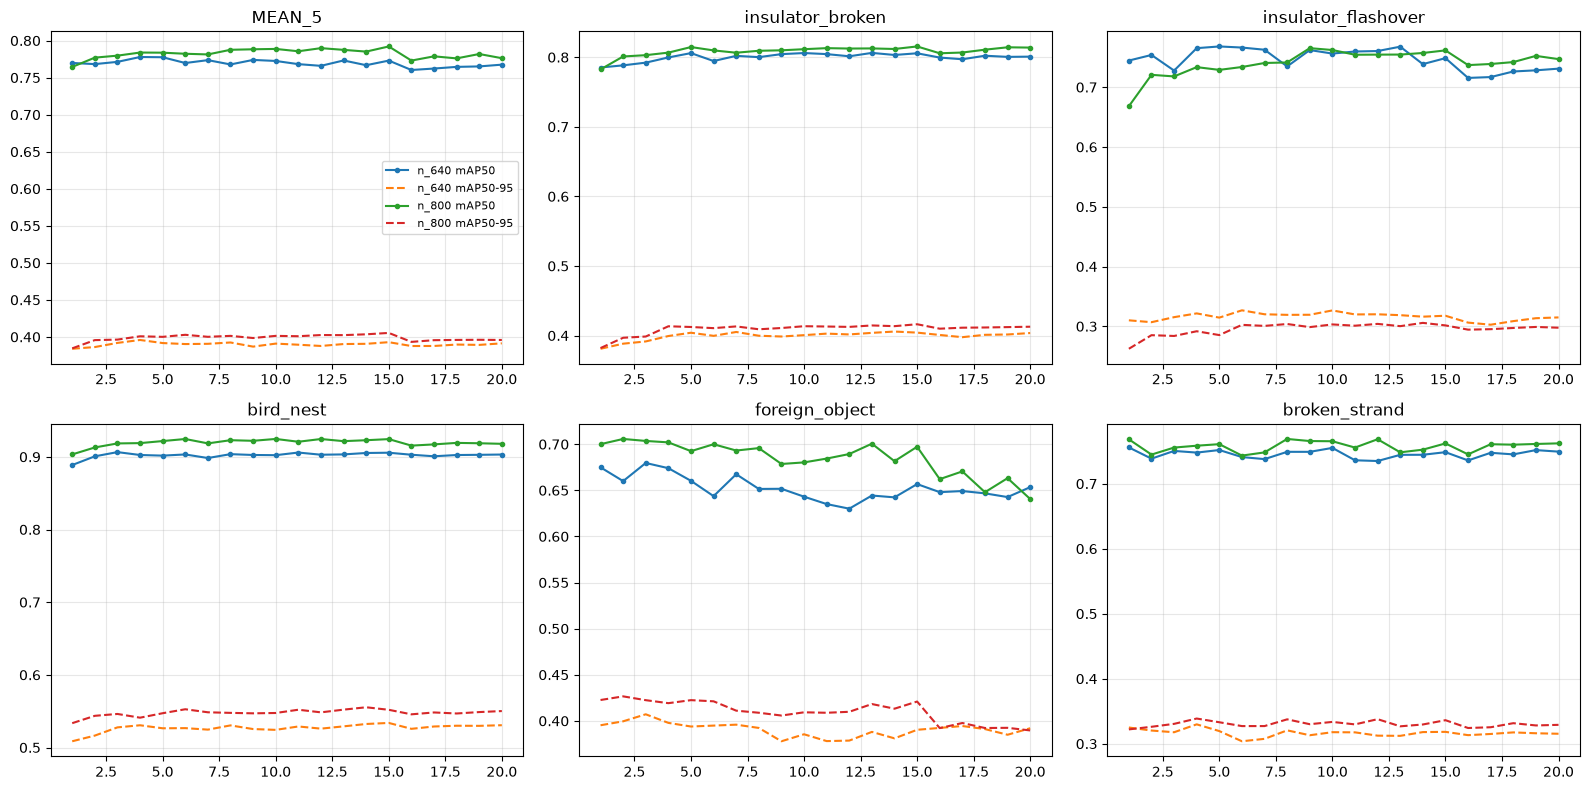

In [5]:
# 5. DIỄN BIẾN THEO EPOCH: bảng AP50 / AP50-95 / gap từng lớp + biểu đồ
import matplotlib.pyplot as plt
from IPython.display import display
E_ = pd.read_csv(EPOCH_CSV)
for k in ["MEAN_5"] + DEFECTS: E_[f"{k}|gap"] = E_[f"{k}|50"] - E_[f"{k}|5095"]
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 50)
for arm, g in E_.groupby("arm"):
    t = g.set_index("epoch")[[f"{k}|{m}" for k in ["MEAN_5"] + DEFECTS for m in ("50", "5095", "gap")]].round(3)
    t.columns = pd.MultiIndex.from_tuples([tuple(c.split("|")) for c in t.columns])
    print(f"\n=== {arm}: mỗi epoch (val_clean_v8 đầy đủ, rect) ==="); display(t)
fig, ax = plt.subplots(2, 3, figsize=(16, 8)); ax = ax.ravel()
for i, k in enumerate(["MEAN_5"] + DEFECTS):
    for arm, g in E_.groupby("arm"):
        ax[i].plot(g.epoch, g[f"{k}|50"], "-o", ms=3, label=f"{arm} mAP50")
        ax[i].plot(g.epoch, g[f"{k}|5095"], "--", label=f"{arm} mAP50-95")
    ax[i].set_title(k); ax[i].grid(alpha=0.3)
ax[0].legend(fontsize=8); plt.tight_layout(); plt.savefig(OUT / "per_class_epochs.png", dpi=110); plt.show()

In [6]:
# 6. KẾT LUẬN: val_clean_v8 KHÔNG RÒ, letterbox vuông (như NCNN): AP50, AP50-95, gap từng lớp cho n_v5 / n_640 / n_800;
#    paired bootstrap AP50 (ảnh) và tỉ lệ bắt ảnh có vết nhỏ (< 1% ảnh) ở conf 0.25
sys.path.insert(0, str(REPO / "scripts")); import eval_v8 as EV
MODELS = {"n_v5@640 (Pi hiện tại)": (INIT, 640)} | {f"n_{sz}@{sz}": (w, sz) for sz, w in BEST.items()}
rows = []
for k, (w, sz) in MODELS.items():   # ultralytics val, rect=False → AP50 + AP50-95 từng lớp
    b = YOLO(str(w)).val(data=str(yaml_noleak), imgsz=sz, batch=16, rect=False, plots=False, verbose=False, workers=0,
                         project=str(OUT / "val"), name=k.split()[0].replace("@", "_"), exist_ok=True).box
    r = {"model": k}
    for i, c in enumerate(b.ap_class_index):
        if 1 <= int(c) <= 5:
            s = SHORT[int(c) - 1]; r[f"{s}|50"], r[f"{s}|5095"] = float(b.ap50[i]), float(b.ap[i]); r[f"{s}|gap"] = r[f"{s}|50"] - r[f"{s}|5095"]
    r["MEAN_5|50"] = np.mean([r[f"{s}|50"] for s in SHORT]); r["MEAN_5|5095"] = np.mean([r[f"{s}|5095"] for s in SHORT])
    r["MEAN_5|gap"] = r["MEAN_5|50"] - r["MEAN_5|5095"]; rows.append(r)
F = pd.DataFrame(rows).set_index("model")[[f"{s}|{m}" for s in ["MEAN_5"] + SHORT for m in ("50", "5095", "gap")]].round(4)
F.columns = pd.MultiIndex.from_tuples([tuple(c.split("|")) for c in F.columns]); print("=== cuối: val_clean_v8 không rò, vuông ==="); display(F)
F.to_csv(OUT / "final_per_class.csv")

NL = [p.name for p in NOLEAK]; idx = {n: i for i, n in enumerate(NL)}; G = EV.gt(NL)
def preds(w, sz, tag):   # cache theo đường dẫn weights (data/label_audit/preflight/sys_<tag>.json)
    f = EV.PF / f"sys_{tag}.json"
    if f.exists() and json.loads(f.read_text()).get("_weights") == str(w): return json.loads(f.read_text())["dets"]
    m = YOLO(str(w)); d = {}
    for p in NOLEAK:
        r = m.predict(str(p), imgsz=sz, conf=0.001, rect=False, verbose=False, device=0)[0]
        d[p.name] = [[int(c), float(s), *bb] for c, s, bb in zip(r.boxes.cls.tolist(), r.boxes.conf.tolist(), r.boxes.xyxyn.tolist())]
    f.write_text(json.dumps({"_weights": str(w), "imgsz": sz, "dets": d})); return d
D = {k: preds(w, sz, f"nb26_{k.split()[0].replace('@', '_')}") for k, (w, sz) in MODELS.items()}
rng = np.random.default_rng(20261016); W = [np.bincount(rng.integers(0, len(NL), len(NL)), minlength=len(NL)).astype(float) for _ in range(1000)]
R, small = {}, {}
for k, d in D.items():
    pre = [EV.prep(d, G[c], c, set(NL), idx) for c in range(1, 6)]; R[k] = np.array([[EV.wap(*x, w) for x in pre] for w in W])
    small[k] = {}
    for c, s in zip(range(1, 6), SHORT):
        pos = [n for n in NL if len(G[c][n]) and max((b[2] - b[0]) * (b[3] - b[1]) for b in G[c][n]) < 0.01]
        small[k][s] = np.mean([any(x[0] == c and x[1] >= 0.25 for x in d[n]) for n in pos]) if pos else np.nan
print("\n=== tỉ lệ bắt ẢNH có vết lỗi nhỏ (< 1% ảnh) ở conf 0.25 ==="); display(pd.DataFrame(small).T.round(3))
keys = list(D); cmp = []
for a_, b_ in [(k, keys[0]) for k in keys[1:]] + ([(keys[2], keys[1])] if len(keys) > 2 else []):
    dd = R[a_] - R[b_]; m = dd.mean(1)
    cmp.append({"so sánh": f"{a_} − {b_}", "MEAN_5": m.mean(), "CI95": f"[{np.percentile(m, 2.5):+.4f}, {np.percentile(m, 97.5):+.4f}]",
                "P(>0)": (m > 0).mean(), **{s: dd[:, i].mean() for i, s in enumerate(SHORT)}})
cmp = pd.DataFrame(cmp); print("\n=== ghép cặp AP50 (bootstrap 1000 vòng trên ảnh) ==="); display(cmp.round(4))
cmp.to_csv(OUT / "final_compare.csv", index=False)
for r in cmp.to_dict("records"): log(f"KẾT LUẬN {r['so sánh']}: MEAN_5 {r['MEAN_5']:+.4f} {r['CI95']} P>0 {r['P(>0)']:.0%}")

Ultralytics 8.4.172  Python-3.12.2 torch-2.14.1+cu126 CUDA:0 (NVIDIA GeForce RTX 4060 Laptop GPU, 8188MiB)
YOLO26n summary (fused): 120 layers, 2,376,201 parameters, 0 gradients, 5.3 GFLOPs
WARNING val: Slow image access detected (ping: 0.60.0 ms, read: 20.720.6 MB/s, size: 150.0 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning d:\Data-Centric-UAV-Powerline-Defect-Detection\Uav-Powerline-Defect-Detection\datasets\v6p5_v9\labels\val_clean_v8... 2123 images, 127 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 2123/2123 516.1it/s 4.1s0.1s
val: New cache created: d:\Data-Centric-UAV-Powerline-Defect-Detection\Uav-Powerline-Defect-Detection\datasets\v6p5_v9\labels\val_clean_v8.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 133/133 5.0it/s 26.6s0.2s
                   all       2123       3788      0.738      0.679      0.714  

MEAN_5                  broken                 flashover                 bird_nest                      FO                  strand                
                            50    5095     gap      50    5095     gap        50    5095     gap        50    5095     gap      50    5095     gap      50    5095     gap
model                                                                                                                                                                     
n_v5@640 (Pi hiện tại)  0.7588  0.3792  0.3796  0.8056  0.4031  0.4025    0.7485  0.3181  0.4304    0.9076  0.5321  0.3754  0.5839  0.3341  0.2498  0.7487  0.3086  0.4401
n_640@640               0.7451  0.3655  0.3796  0.7915  0.3904  0.4011    0.7388  0.3159  0.4229    0.9069  0.5285  0.3784  0.5615  0.3098  0.2517  0.7267  0.2827  0.4440
n_800@800               0.7581  0.3793  0.3788  0.8017  0.4078  0.3939    0.7328  0.2982  0.4346    0.9120  0.5432  0.3688  0.6033  0.3472  0.2560  0.7407  0.3000  0.4407


=== tỉ lệ bắt ẢNH có vết lỗi nhỏ (< 1% ảnh) ở conf 0.25 ===


,broken,flashover,bird_nest,FO,strand
n_v5@640 (Pi hiện tại),0.682,0.833,0.950,0.429,0.444
n_640@640,0.697,0.722,0.959,0.429,0.333
n_800@800,0.711,0.778,0.950,0.571,0.444



=== ghép cặp AP50 (bootstrap 1000 vòng trên ảnh) ===


,so sánh,MEAN_5,CI95,P(>0),broken,flashover,bird_nest,FO,strand
0,n_640@640 − n_v5@640 (Pi hiện tại),-0.0186,"[-0.0314, -0.0056]",0.003,-0.0132,-0.0116,0.0004,-0.0415,-0.0274
1,n_800@800 − n_v5@640 (Pi hiện tại),-0.0014,"[-0.0229, +0.0189]",0.447,-0.0051,-0.0167,0.0077,0.0173,-0.0103
2,n_800@800 − n_640@640,0.0172,"[-0.0029, +0.0366]",0.952,0.0081,-0.0051,0.0072,0.0588,0.0171


KẾT LUẬN n_640@640 − n_v5@640 (Pi hiện tại): MEAN_5 -0.0186 [-0.0314, -0.0056] P>0 0%
KẾT LUẬN n_800@800 − n_v5@640 (Pi hiện tại): MEAN_5 -0.0014 [-0.0229, +0.0189] P>0 45%
KẾT LUẬN n_800@800 − n_640@640: MEAN_5 +0.0172 [-0.0029, +0.0366] P>0 95%
